# Exercise 10: Autoencoders 

## About Dataset

The data contains information from the 1990 California census. The data pertains to the houses found in a given California district and some summary stats about them based on the 1990 census data. Be warned the data aren't cleaned so there are some preprocessing steps required! The columns of dataset are as follows:
- longitude
- latitude
- housingmedianage
- total_rooms
- total_bedrooms
- population
- households
- median_income
- medianhousevalue
- ocean_proximity

More information about the feature can be found [here](https://www.linkedin.com/pulse/analyzing-california-housing-prices-dataset-data-science-anand-dubey-jmdhf/)

[California Housing Dataset](https://www.kaggle.com/datasets/vikramtiwari/california-housing-dataset-ml-crash-course) from Kaggle. Dataset can be found also from Moodle.

## Dimensionality Reduction

Dimensionality Reduction is the process of reducing the number of dimensions in the data either by excluding less useful features (Feature Selection) or transform the data into lower dimensions (Feature Extraction). Dimensionality reduction prevents overfitting. Overfitting is a phenomenon in which the model learns too well from the training dataset and fails to generalize well for unseen real-world data.

## Exercise description

Use AutoEncoders for dimensionality reduction i.e. use the bottleneck layer  to reduce the dimensions. This process can be viewed as feature extraction.

### Hints

- The number of neurons in the layers of the encoder will be decreasing, for example 32 -> 7
- The number of neurons in the layers of the decoder will be increasing, for example 7 -> 32 
- The code size/ the number of neurons in bottleneck must be less than the number of features in the data
- Before feeding the data into the AutoEncoder the data must definitely be scaled between 0 and 1 using MinMaxScaler -> Use sigmoid activation function in the output layer which outputs values between 0 and 1.

__This exercises HAVE TO be done in CSC Puhti cloud environment.__

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

I0000 00:00:1795457539.974963 1392392 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795457539.990712 1392392 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795457541.340820 1392392 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795457544.410333 1392392 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

## 2. Load the data

This uses the Google ML Crash Course version of the dataset, which comes already split into
`california_housing_train.csv` (17,000 rows) and `california_housing_test.csv` (3,000 rows).
Both files are assumed to sit in the same folder as this notebook on Puhti — adjust the paths
below if yours are stored elsewhere.

Note: this version does **not** include the `ocean_proximity` column mentioned in the exercise
intro, and it has no missing values — it is a cleaned, numeric-only variant of the same dataset,
so the preprocessing below is simpler than it would be for the raw Kaggle file.

In [2]:
train_df = pd.read_csv('california_housing_train.csv')
test_df = pd.read_csv('california_housing_test.csv')

print('train_df shape:', train_df.shape)
print('test_df shape :', test_df.shape)
train_df.head()

train_df shape: (17000, 9)
test_df shape : (3000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


## 3. Inspect the data (dtypes, missing values, basic stats)

In [3]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


In [4]:
print('Missing values (train):')
print(train_df.isna().sum())
print('\nMissing values (test):')
print(test_df.isna().sum())

Missing values (train):
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64

Missing values (test):
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64


In [5]:
train_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 4. Preprocessing

Unlike the raw Kaggle file, this version is already clean: every column is numeric and there
are no missing values (confirmed above), so no imputation or one-hot encoding is needed.

The only required step per the assignment hints is scaling every feature to `[0, 1]` with
`MinMaxScaler`, since the autoencoder's output layer uses `sigmoid`.

## 5. Separate features/target and scale

We keep `median_house_value` out of the autoencoder input — the exercise is about reducing the
dimensionality of the *features*, not reconstructing the target. We use the provided train/test
files directly instead of making our own split.

Important: the scaler is **fit only on the train set**, then just applied (`transform`, not
`fit_transform`) to the test set — otherwise information from the test set would leak into
training.

In [6]:
feature_cols = [c for c in train_df.columns if c != 'median_house_value']

X_train = train_df[feature_cols].values
X_test = test_df[feature_cols].values

y_train = train_df['median_house_value'].values
y_test = test_df['median_house_value'].values

print('Number of input features:', X_train.shape[1])

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train shape:', X_train_scaled.shape)
print('Test shape :', X_test_scaled.shape)
print('Train min/max after scaling:', X_train_scaled.min(), X_train_scaled.max())
print('Test min/max after scaling (can be slightly outside [0,1], that is expected):',
      X_test_scaled.min(), X_test_scaled.max())

Number of input features: 8
Train shape: (17000, 8)
Test shape : (3000, 8)
Train min/max after scaling: 0.0 1.0
Test min/max after scaling (can be slightly outside [0,1], that is expected): 0.0 1.0


## 6. Build the Autoencoder

Following the hints:
- Encoder: decreasing layer sizes, e.g. `n_features -> 32 -> 16 -> 7` (bottleneck)
- Decoder: increasing layer sizes, mirrored: `7 -> 16 -> 32 -> n_features`
- Bottleneck size (7) is smaller than the number of input features, so this is genuine dimensionality reduction.
- Output layer uses `sigmoid`, matching the `[0, 1]` scaled input, and the model is trained to reconstruct its own input (`X -> X`).

In [7]:
n_features = X_train_scaled.shape[1]
bottleneck_dim = 7  # must be < n_features

assert bottleneck_dim < n_features, 'Bottleneck must be smaller than the number of input features'

input_layer = keras.Input(shape=(n_features,))

# Encoder: decreasing
x = layers.Dense(32, activation='relu')(input_layer)
x = layers.Dense(16, activation='relu')(x)
bottleneck = layers.Dense(bottleneck_dim, activation='relu', name='bottleneck')(x)

# Decoder: increasing (mirrored)
x = layers.Dense(16, activation='relu')(bottleneck)
x = layers.Dense(32, activation='relu')(x)
output_layer = layers.Dense(n_features, activation='sigmoid')(x)

autoencoder = keras.Model(inputs=input_layer, outputs=output_layer, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

E0000 00:00:1795457594.032998 1392392 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 7)              │           119 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,871 (7.31 KB)

 Trainable params: 1,871 (7.31 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the Autoencoder

In [8]:
history = autoencoder.fit(
    X_train_scaled, X_train_scaled,
    validation_data=(X_test_scaled, X_test_scaled),
    epochs=100,
    batch_size=32,
    shuffle=True,
    verbose=1,
)

Epoch 1/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 614us/step - loss: 0.0233 - val_loss: 0.0043
Epoch 2/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step - loss: 0.0034 - val_loss: 0.0028
Epoch 3/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step - loss: 0.0027 - val_loss: 0.0024
Epoch 4/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 466us/step - loss: 0.0024 - val_loss: 0.0022
Epoch 5/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step - loss: 0.0021 - val_loss: 0.0019
Epoch 6/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 463us/step - loss: 0.0018 - val_loss: 0.0016
Epoch 7/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - loss: 0.0016 - val_loss: 0.0015
Epoch 8/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step - loss: 0.0015 - val_loss: 0.0014
Epoch 9/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step - loss: 0.0014 - val_loss: 0.0014
Epoch 10/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 457us/step - loss: 0.0013 - val_loss: 0.0012
Epoch 11/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 466us/step - loss: 8.6344e-04 - val_loss: 6.1540e-04
Epoch 12/10

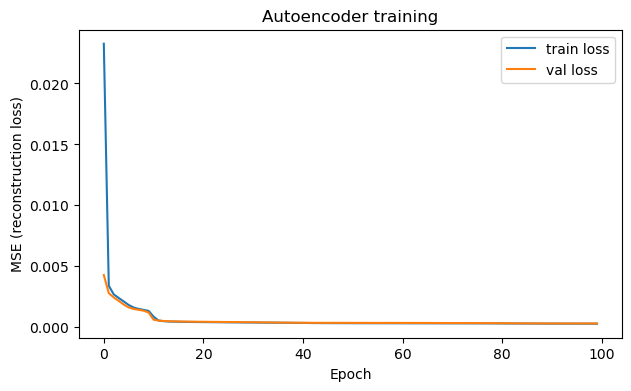

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch')
plt.ylabel('MSE (reconstruction loss)')
plt.title('Autoencoder training')
plt.legend()
plt.show()

## 8. Extract the reduced-dimension features (encoder output)

This is the actual deliverable of the exercise: a separate `encoder` model that stops at the bottleneck layer, so we can transform any row into its 7-number compressed representation.

In [10]:
encoder = keras.Model(inputs=input_layer, outputs=bottleneck, name='encoder')

X_train_encoded = encoder.predict(X_train_scaled)
X_test_encoded = encoder.predict(X_test_scaled)

print('Original feature count :', X_train_scaled.shape[1])
print('Reduced feature count  :', X_train_encoded.shape[1])

pd.DataFrame(X_train_encoded, columns=[f'latent_{i}' for i in range(bottleneck_dim)]).head()

532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 214us/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 271us/step
Original feature count : 8
Reduced feature count  : 7


,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6
0,0.0,0.657492,1.178382,0.0,1.277858,0.0,4.044566
1,0.0,0.468655,1.094170,0.0,0.894147,0.0,3.791076
2,0.0,0.918926,1.532133,0.0,2.017988,0.0,4.324763
3,0.0,0.751104,1.294068,0.0,1.907957,0.0,3.879818
4,0.0,0.794643,1.495741,0.0,1.836269,0.0,4.203541


## 9. Sanity check: does the reduced representation preserve useful structure?

A quick, simple check: correlate each of the 7 latent features with `median_house_value` (which we held out of the autoencoder entirely). If the autoencoder learned something meaningful, at least some latent dimensions should correlate with the target, even though it never saw it during training.

In [11]:
# y_train / y_test (median_house_value) were already set aside in Step 5,
# and were never shown to the autoencoder during training.
latent_df = pd.DataFrame(X_train_encoded, columns=[f'latent_{i}' for i in range(bottleneck_dim)])
latent_df['median_house_value'] = y_train

latent_df.corr()['median_house_value'].sort_values(ascending=False)

median_house_value    1.000000
latent_5              0.000012
latent_2             -0.107944
latent_4             -0.220353
latent_1             -0.370624
latent_6             -0.496995
latent_0                   NaN
latent_3                   NaN
Name: median_house_value, dtype: float64

# Conclusion

__NOTE: Conclusion is one evaluation criterion for the exercise, so pay attention to writing this__

Write conclusion:

- Results
- Development process 
- etc. 